# 08 · Реальные бланки КТГ: семантика, feature engineering и ограниченные модели

## tl;dr

Этот ноутбук проверяет, сколько качества UCI сохраняется при ограничении входов до показателей, похожих на доступные в больничных отчётах. **Совпадение названия и единиц не доказывает совпадение измерения.** Модель для полного набора UCI нельзя применять к бланку, заполнив отсутствующие показатели нулями.

Ниже — выполненный поиск, три экспортированных варианта для разных входов, проверка пропусков/единиц и разбор прикреплённого примера. Существующие модели и кластеризация сохранены. Результаты этого эксперимента — исследовательские: перенос на больничное устройство ещё не проверен.

### Выполненный результат

| Вход | Outer macro-F1 | Test macro-F1 | Recall патологии на test |
|---|---:|---:|---:|
| core2 | 0.475 | 0.474 | 2.9% |
| common3 | 0.522 | 0.546 | 34.3% |
| sisporto9 | 0.854 | 0.844 | 88.6% |

Три условно общих показателя не дают приемлемой полноты выявления патологии. Девять нативных измерений сохраняют значительно больше качества, но недоступны из приложенного бланка. Engineering не устраняет отсутствие измерений. Test известен; это исследование переносимости признаков, не клиническая валидация.

## Context & Methods · постановка до просмотра новых результатов

**Целевой продукт:** приложение для ведения беременности, дородовые КТГ, аппарат заранее неизвестен (уточнение пользователя). Общий формат принимает значения разных бланков и сохраняет неизвестное явно. Универсальная совместимость модели не следует из универсальности формы ввода.

**Учебная цель:** экспертный класс NSP (1 normal / 2 suspect / 3 pathologic). Он не является диагнозом гипоксии, вероятностью плохого исхода или меткой «8 из 8» конкретного прибора. Единица доступной группировки — исходная запись `source_file`; независимость пациенток не доказана.

### План

1. Сверить все 21 исходных признаков с XLS, восстановить число событий и экспозицию, проверить пропуски/нули/единицы и распределения.
2. Сопоставить больничные показатели по определениям, а не только по названиям. Отдельно сохранить значения, которых нет в обучающем UCI.
3. Обучить модели заново на трёх контрактах входа. `core2`: LB+AC; `common3`: LB+AC+сумма DL/DS/DP; `sisporto9`: LB, AC, UC, DL, DP, ASTV, MSTV, ALTV, MLTV. Последний — нативный ориентир, на фотографии этих 9 измерений нет.
4. Для каждого профиля совместно подобрать семейство, параметры и режим признаков внутри 5×3 grouped nested CV. Режимы: исходные / исходные+производные. A/B(SqrtBalanced/Balanced)/C(OvR)/D(иерархия)/логистика. Общие внешние и внутренние фолды из audited v2. Категории исходного файла, CLASS и выводы прибора в X не входят.
5. Grid CatBoost: depth=3/5, iterations=300/600, L2=3/10, learning_rate=.06. Логистика: C=.1/1/10 × class_weight=None/Balanced. На профиль 92 кандидата; всего 4140 внутренних оценок + 828 финальных. Это конечный проверенный grid, не гарантия глобального оптимума. Веса классов не комбинируются с oversampling.
6. Выбирать по mean inner segment macro-F1; tie — log loss. Внешний фолд оценивает выбор семейства и engineering, с фиксированным argmax. Отдельные raw/engineered процедуры позволяют увидеть пользу engineering без выбора по test.
7. Финальный grid использует train; деревья и скейлеры обучаются только на train. Пять моделей по фолдам усредняют готовые вероятности; ансамбль принимается при выигрыше ≥.01 macro-F1 на validation. Затем scalar temperature обучается на validation, сохраняет argmax. Порог на патологию в этой ветке не подбирается. Нет рефита на train+validation после калибровки.
8. Известный исследованию test используется для описательной проверки после фиксации решений. Это **не новая слепая внешняя проверка**. Доверительные интервалы resample исходные файлы, а не отдельные сегменты; они не включают неопределённость повторного обучения и выбора модели. Nested score не оценивает отдельный финальный выбор ансамбля/калибровку на validation.

### Key Assumptions

`common3` — условный proxy: сумма категорий децелераций UCI предполагает непересекающиеся категории событий. Совпадение с общим числом децелераций другого производителя ещё требуется доказать на одних и тех же сигналах. Поэтому ограничение признаков проверяет потерю информации **внутри UCI**, но не доказывает переносимость на бланк.

In [3]:
from pathlib import Path
import sys,json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, average_precision_score
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.features.ctg_report_features import PROFILES,ReportFeatures,uci_profile,audit_hospital_report,report_to_common3
from src.features.ctg_report_evidence import prepare_evidence,temporal_counterexample,example_report,SOURCES,INPUTS
from src.training.ctg_report_models import OUT,EXPORT,context,run_nested,run_final,class_details,bootstrap_results
from src.training.ctg_experiments import CTG_FEATURES
data,exposure,dictionary,mapping,example_audit=prepare_evidence()
_,fingerprint,cache,versions=context()
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
def show_save(name):
    plt.gcf().savefig(OUT/name,dpi=140,bbox_inches='tight')
    plt.show()
print('Fingerprint:',fingerprint)
display(pd.Series(versions,name='version').to_frame())

Fingerprint: 54e923bb77b4598944f5b5075ab2f03f00aaf43d38364d92b534a83e2001ef1c


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.9.1
catboost,1.2.10
joblib,1.6.0


## Data · первичные значения и экспозиция

Источник — официальный UCI Cardiotocography и листы Description, Raw Data, Data исходного CTG.xls. Официальная публикация содержит 2126 измерений и 21 признак. [UCI](https://archive.ics.uci.edu/dataset/193/cardiotocography), DOI 10.24432/C51S4N, CC BY 4.0.

Проверка ниже вычисляет, а не предполагает: опубликованные AC/FM/UC/DL/DS/DP равны сырым счётчикам, делённым на `e−b` секунд. Не перепутать events/second с числом событий, events/minute или частотой за час. Исходные длительности сохраняются для аудита; в этой модели длительность не предиктор. Результат проверки всех строк — в отдельном CSV.

In [5]:
display(pd.read_csv(OUT/'event_rate_reconstruction.csv'))
display(dictionary[['feature','definition','missing','in_core2','in_sisporto9']])
display(dictionary[['feature','train_min','train_median','train_max','train_zero_pct','train_nonzero_files']].round(4))
display(exposure.groupby('split').agg(n=('NSP','size'),files=('source_file','nunique'),
    duration_min=('duration_s',lambda x:x.min()/60),duration_median=('duration_s',lambda x:x.median()/60),
    duration_max=('duration_s',lambda x:x.max()/60)))
display(data.groupby(['split','NSP']).agg(segments=('NSP','size'),files=('source_file','nunique')))
assert dictionary.missing.sum()==0
assert data.groupby('source_file').split.nunique().max()==1
assert data.groupby('feature_duplicate_group').split.nunique().max()==1
assert np.allclose(data.Width,data.Max-data.Min)

,feature,unit,denominator,rows,max_abs_error
0,AC,events/second,e-b,2126,0.0
1,FM,events/second,e-b,2126,0.0
2,UC,events/second,e-b,2126,0.0
3,DL,events/second,e-b,2126,0.0
4,DS,events/second,e-b,2126,0.0
5,DP,events/second,e-b,2126,0.0


,feature,definition,missing,in_core2,in_sisporto9
0,LB,Базальная линия SisPorto,0,True,True
1,AC,Акцелерации / s,0,True,True
2,FM,Шевеления / s,0,False,False
3,UC,Сокращения матки / s,0,False,True
4,DL,Лёгкие децелерации / s,0,False,True
5,DS,Тяжёлые децелерации / s,0,False,False
6,DP,Пролонгированные децелерации / s,0,False,True
7,ASTV,% abnormal STV SisPorto,0,False,True
8,MSTV,Mean STV SisPorto (native definition),0,False,True
9,ALTV,% abnormal LTV SisPorto,0,False,True


,feature,train_min,train_median,train_max,train_zero_pct,train_nonzero_files
0,LB,110.0,133.0000,160.0000,0.0000,227
1,AC,0.0,0.0017,0.0179,40.8088,162
2,FM,0.0,0.0000,0.4553,62.8676,122
3,UC,0.0,0.0043,0.0149,15.0000,181
4,DL,0.0,0.0000,0.0154,57.4265,106
5,DS,0.0,0.0000,0.0014,99.4853,2
6,DP,0.0,0.0000,0.0053,92.1324,24
7,ASTV,12.0,48.0000,87.0000,0.0000,227
8,MSTV,0.2,1.2000,6.3000,0.0000,227
9,ALTV,0.0,0.0000,91.0000,57.1324,134


,n,files,duration_min,duration_median,duration_max
split,,,,,
test,425,68,2.566667,13.550000,59.983333
train,1360,227,1.950000,13.033333,53.900000
validation,341,57,4.233333,13.783333,37.700000


segments  files
split      NSP                 
test       1         332     55
           2          58     23
           3          35     10
train      1        1057    177
           2         191     81
           3         112     33
validation 1         266     43
           2          46     19
           3          29      7

### Распределения всех исходных признаков · train

Нули событий сохранены: «событий не было» отличается от «не измеряли». Из-за малого числа записей DS с ненулевым значением тяжёлую категорию не используем как отдельный устойчивый предиктор. В common3 она остаётся в явно описанной сумме событий. Tendency — категория −1/0/1, гистограммные поля не являются показателями осцилляций из бланка. Эти поля не входят ни в один из трёх профилей.

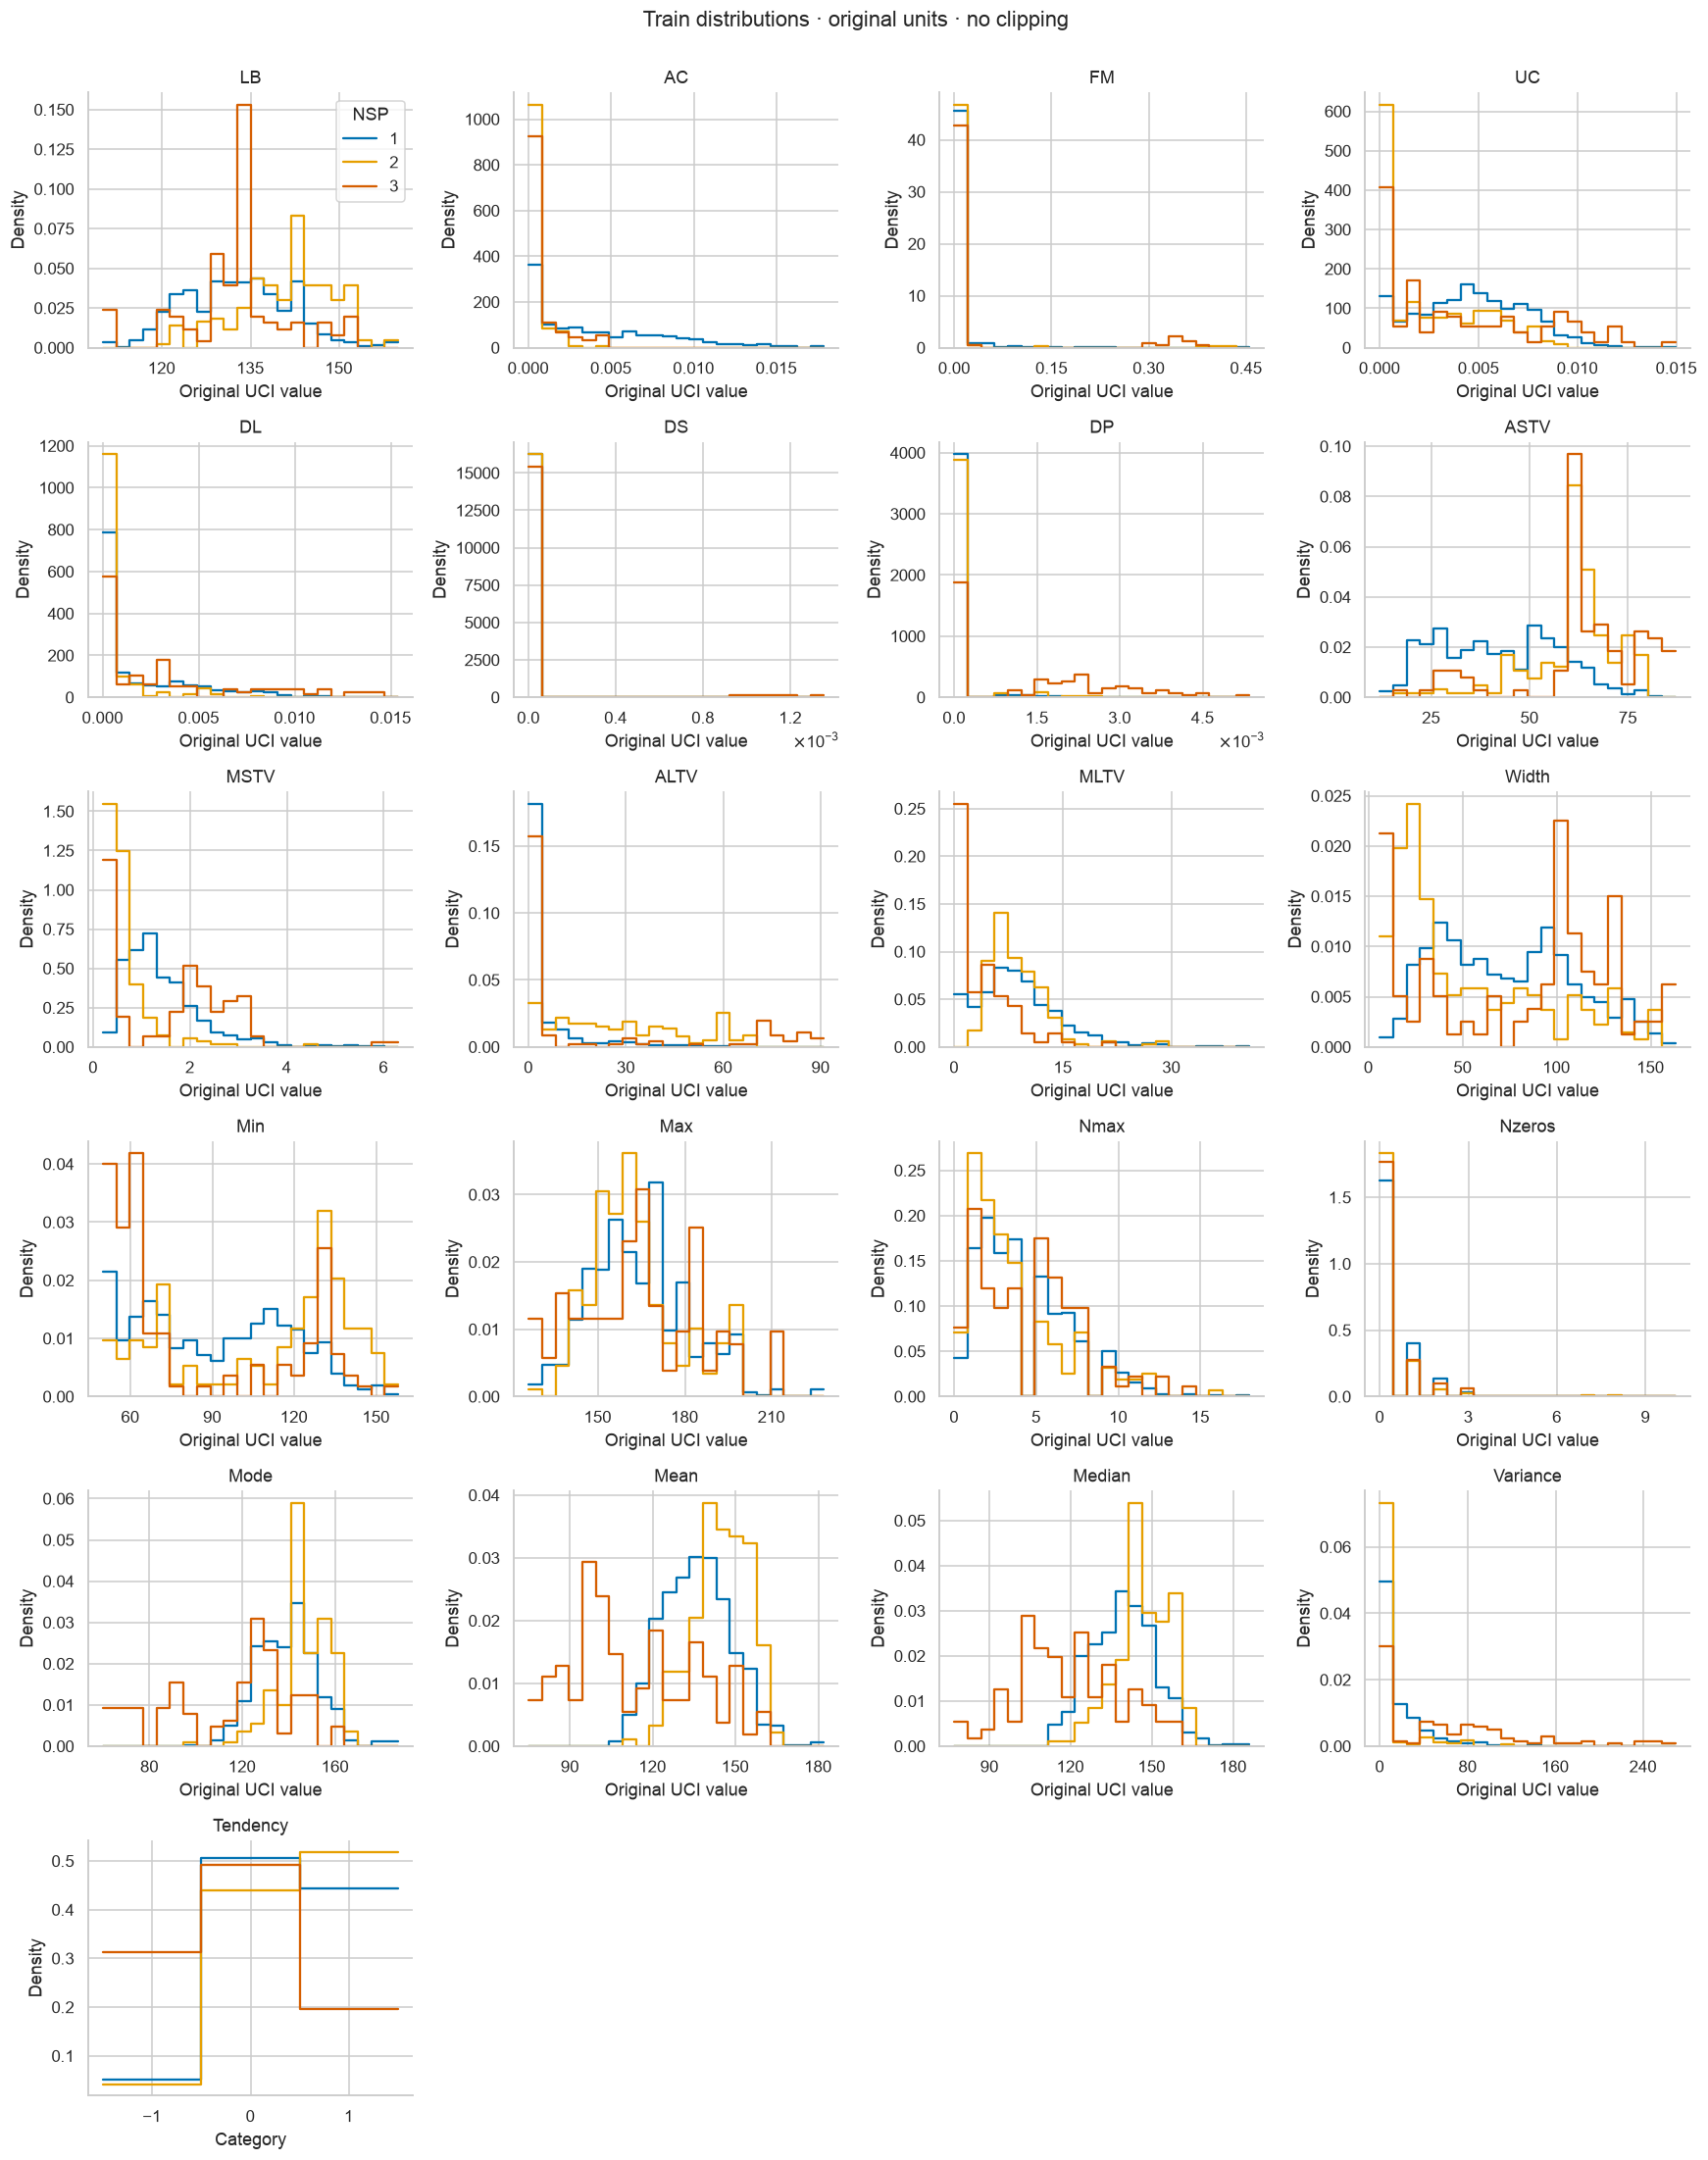

In [7]:
train=data[data.split=='train'].copy()
fig,axes=plt.subplots(6,4,figsize=(16,20));axes=axes.ravel()
for ax,name in zip(axes,CTG_FEATURES):
    # Shared bin edges are essential when comparing class densities, especially
    # when one class is all zero and another contains rare nonzero events.
    edges=(np.array([-1.5,-.5,.5,1.5]) if name=='Tendency'
           else np.histogram_bin_edges(train[name],bins=22))
    for label,color in [(1,'#0072b2'),(2,'#e69f00'),(3,'#d55e00')]:
        sns.histplot(train.loc[train.NSP==label,name],bins=edges,stat='density',element='step',
                     fill=False,color=color,ax=ax,label=str(label))
    ax.set(title=name,ylabel='Density');ax.set_xlabel('Original UCI value')
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.ticklabel_format(axis='x',style='sci',scilimits=(-3,4),useMathText=True)
    if name=='Tendency':ax.set_xticks([-1,0,1]);ax.set_xlabel('Category')
for ax in axes[len(CTG_FEATURES):]:ax.axis('off')
axes[0].legend(title='NSP');fig.suptitle('Train distributions · original units · no clipping',y=1.0)
fig.tight_layout();show_save('01_original_feature_distributions.png')

## Что можно перенести из реального отчёта

Таблица ниже фиксирует пригодность каждого поля. `conditional` и `conditional_proxy` не означают подтверждённую эквивалентность.

В первичной работе по SisPorto 2 описаны собственные правила базальной линии, акцелераций, вариабельности и разбиение децелераций по длительности. [Авторы, 2004](https://www.sciencedirect.com/science/article/abs/pii/S030121150400212X). Правила менялись между версиями; определения позднего SisPorto нельзя автоматически приписывать каждому полю исторического UCI. [Первичное исследование с таблицей определений](https://pmc.ncbi.nlm.nih.gov/articles/PMC7516409/).

В руководстве Сономед отдельно определены ВКИ/vSTV, STV по 3.75-секундным эпохам и минутная LTV; значимость децелерации связана с площадью потерянных ударов. Расчёт вариабельности исключает некоторые минуты с потерями/децелерациями. [Руководство производителя, разделы 6.3–6.8](https://cordismed.ru/image/pdf/spektromed-sonomed-200-instrukcija.pdf). Это объясняет похожие строки, но **не устанавливает модель устройства на фото**. Похожая форма встречается и в [руководстве MFMon](https://usontec.com/uploads/s/9/2/c/92ckun9gej9h/file/raxxmfuv.pdf).

У Dawes–Redman STV измеряется через изменения средних пульсовых интервалов в 3.75-секундных эпохах; простой перевод ms→bpm не превращает её в SisPorto MSTV. Порог и контекст анализа зависят от метода. [Официальное руководство Huntleigh](https://www.huntleigh-diagnostics.com/wp-content/uploads/2025/07/749339EN-1.1-English-DAWES-REDMAN-CTG-ANALYSIS-Clinical-Application-Guide.pdf).

In [9]:
pd.set_option('display.max_colwidth',160)
display(mapping)

,hospital_field,UCI_candidate,status,reason
0,"Базальная ЧСС, BPM",LB,conditional,Единицы совпадают; алгоритм базальной линии и версия прибора требуют проверки
1,"Акцелерации >15 BPM, ≥15 s",AC,conditional,count/(60×duration_min); совпадения порога недостаточно для равенства детекторов
2,"Акцелерации >10 BPM, ≥15 s",нет,incompatible,Другой порог: не подставлять в AC и не складывать с >15
3,"Все децелерации >15 BPM, ≥15 s",DL+DS+DP,conditional_proxy,Сумма опубликованных категорий UCI; сверить взаимоисключение и правила детектора
4,Децелерации >20 потерянных ударов,нет,incompatible,"Площадь события, не амплитуда >20 BPM и не число DP"
5,"STV, ms / BPM",MSTV,incompatible,Эпохальная STV и исходная SisPorto MSTV не взаимозаменяемы
6,"ВКИ, ms / BPM",нет,incompatible,В руководстве Сономед это vSTV от удара к удару; не доказано равенство UCI MSTV
7,Минуты высокой / низкой вариабельности,ASTV / ALTV,incompatible,Эпизоды с иными правилами; длительность / время записи не восстанавливает ASTV/ALTV
8,Амплитуда осцилляций,Width / MLTV,incompatible,Минутная амплитуда не ширина общей гистограммы; MLTV требует нативного определения
9,"Частота осцилляций, 1/min",Nmax / Nzeros,incompatible,Частота во времени не число пиков/нулей гистограммы


### Почему нельзя восстановить STV из агрегатов

Ниже математический пример, не клинические сигналы и не обучающие наблюдения. Две последовательности имеют одинаковую гистограмму (все её статистики одинаковы), но разный порядок точек и разную среднюю соседнюю разность. Следовательно, гистограмма не определяет временную вариабельность. Эта игрушечная соседняя разность не заявляется точной реализацией STV какого-либо прибора.

,sequence,mean,minimum,maximum,variance,mean_abs_adjacent_bpm
0,two_blocks,130.0,120.0,140.0,100.0,0.645161
1,alternating,130.0,120.0,140.0,100.0,20.000000


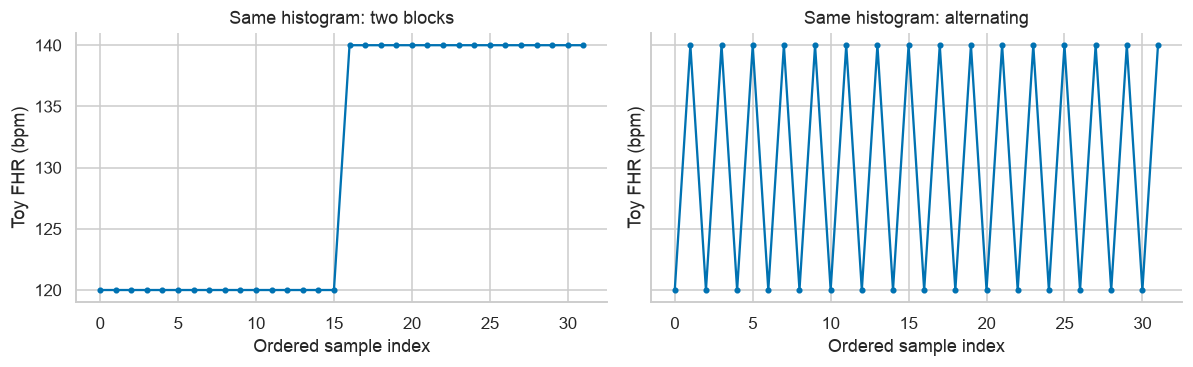

In [11]:
toy,slow,fast=temporal_counterexample();display(toy)
fig,axes=plt.subplots(1,2,figsize=(11,3.5),sharey=True)
for ax,x,title in zip(axes,[slow,fast],['Same histogram: two blocks','Same histogram: alternating']):
    ax.plot(x,marker='.',color='#0072b2');ax.set(xlabel='Ordered sample index',ylabel='Toy FHR (bpm)',title=title)
fig.tight_layout();show_save('02_temporal_counterexample.png')

## Разбор прикреплённого примера

В JSON сохранена ручная транскрипция чисел; устройство, версия ПО, срок и антенатальный/интранатальный контекст не выдуманы. Число 8/8 и галочки исключены: это выводы настроенной пользовательской системы. У этого примера нет независимой метки NSP.

- При 17 min частота акцелераций >15 BPM: 1/1020 событий в секунду. Строка >10 BPM содержит 5 событий и не подменяет первую.
- 13/17 — доля времени эпизодов высокой вариабельности в данном отчёте. Она не восстанавливает ASTV/ALTV.
- 17×(1−.085) — номинальное время без потерь. Оно не сообщает распределение артефактов по минутам и не определяет точную экспозицию детектора событий.
- Согласованность ms и BPM проверяем локальным приближением ΔBPM≈STV_ms×LB²/60000. Это проверка единиц, не эквивалентности алгоритмов.

Адаптер показывает доступные преобразования, маску пропусков и причины несовместимости. Для этого изображения выдача модельного класса заблокирована до проверки контракта измерений. Это не оценка состояния плода.

In [13]:
report=example_report()
display(pd.Series({k:v for k,v in report.items() if isinstance(v,(float,int))},name='transcribed_value').to_frame())
display(pd.Series(example_audit['derived'],name='unit_checks_and_descriptors').to_frame())
print('Adapter status:',example_audit['status'])
display(pd.DataFrame({'blocking_reason':example_audit['issues']}))
try:
    report_to_common3(report)
    raise AssertionError('Unverified hospital report must not reach inference')
except ValueError as exc:
    print('Correctly refused incompatible inference:',exc)
missing_example=dict(report,decelerations_15_15_count=None)
assert audit_hospital_report(missing_example)['missing_mask']['decelerations_15_15_count']
assert not example_audit['missing_mask']['decelerations_15_15_count']
print('Missing != zero: checked')
from src.features.ctg_pregnancy_app import prepare_pregnancy_app_record
app_record=prepare_pregnancy_app_record(report)
(INPUTS/'example_app_record.json').write_text(json.dumps(app_record,ensure_ascii=False,indent=2))
print('Unknown-device storage:',app_record['storage_status'])
print('Clinical model eligibility:',app_record['model_prediction_eligible'])
display(pd.DataFrame({'app_notice':app_record['notices']}))

Adapter status: blocked_incompatible_measurements
Correctly refused incompatible inference: Unverified metadata: device; Unverified metadata: software_version; Unverified metadata: analysis_context; Unverified metadata: gestational_weeks; No verified measurement bridge to UCI SisPorto 2; Event denominator (wall-time vs valid signal) is unverified
Missing != zero: checked
Unknown-device storage: accepted_with_unknowns
Clinical model eligibility: False


,transcribed_value
duration_min,17.0
signal_loss_pct,8.5
baseline_bpm,131.4
accelerations_10_15_count,5.0
accelerations_15_15_count,1.0
decelerations_15_15_count,0.0
decelerations_over_20_lost_beats_count,0.0
high_variation_min,13.0
low_variation_min,0.0
sinusoidal_min,0.0


,unit_checks_and_descriptors
duration_s,1020.000000
accelerations_per_s,0.000980
decelerations_per_s,0.000000
high_variation_fraction,0.764706
low_variation_fraction,0.000000
sinusoidal_fraction,0.000000
nominal_nonlost_min,15.555000
baseline_rr_ms,456.621005
stv_bpm_linear_unit_check,2.187022


,blocking_reason
0,Unverified metadata: device
1,Unverified metadata: software_version
2,Unverified metadata: analysis_context
3,Unverified metadata: gestational_weeks
4,No verified measurement bridge to UCI SisPorto 2
5,Event denominator (wall-time vs valid signal) is unverified


,app_notice
0,Для дородового сценария нужно подтвердить контекст записи
1,Срок беременности не указан
2,Аппарат не указан; показатели сохранены с исходными единицами
3,Совместимость измерений с обученной моделью не подтверждена


## Feature engineering · формулы и защита от утечки

Обучаемые профили содержат только признаки, реально вычисляемые из соответствующего поднабора UCI. Производные детерминированы: RR=60000/LB; log1p(rate×1200); наличие событий; для common3 — log((D×1200+.5)/(A×1200+.5)) и баланс (A−D)/(A+D+1) в 20-минутном масштабе. .5 — фиксированная стабилизирующая константа, не наблюдавшееся событие. Для нативного профиля добавлены доли, их произведение и вариабельности относительно LB. Производные не создают новую информацию; пользу проверяет CV.

Вариабельность из фотографии, проценты потерь, срок беременности, частоты осцилляций и синусоидальные минуты сохраняются для будущей размеченной больничной базы. Из UCI для них нет обоснованных обучающих значений. **Обучать на синтетически подставленных «аналогах» было бы ошибкой.**

При структурно отсутствующем поле выбирается отдельный профиль модели. При пропуске обязательного значения предсказание прекращается. Маски качества сохраняются в аудите; обучать влияние таких масок пока не на чем, потому что UCI не содержит реального распределения этих пропусков. CatBoost работает без скейлера; у логистики RobustScaler заново fit внутри каждого fit-фолда, затем сохраняется внутри bundle и отдельно.

In [15]:
for profile in PROFILES:
    x=uci_profile(train,profile)
    engineered=ReportFeatures(profile,True).fit_transform(x)
    print(profile,':',len(x.columns),'raw →',len(engineered.columns),'engineered')
    display(pd.DataFrame({'feature':engineered.columns,'missing':engineered.isna().sum().values}))

core2 : 2 raw → 5 engineered
common3 : 3 raw → 10 engineered
sisporto9 : 9 raw → 23 engineered


,feature,missing
0,baseline_bpm,0
1,accelerations_per_s,0
2,baseline_rr_ms,0
3,accelerations_log_events_per_20min,0
4,accelerations_present,0


,feature,missing
0,baseline_bpm,0
1,accelerations_per_s,0
2,decelerations_per_s,0
3,baseline_rr_ms,0
4,accelerations_log_events_per_20min,0
5,accelerations_present,0
6,decelerations_log_events_per_20min,0
7,decelerations_present,0
8,decel_accel_log_ratio,0
9,event_balance,0


,feature,missing
0,baseline_bpm,0
1,accelerations_per_s,0
2,contractions_per_s,0
3,light_decelerations_per_s,0
4,prolonged_decelerations_per_s,0
5,abnormal_stv_pct,0
6,mean_stv_sisporto,0
7,abnormal_ltv_pct,0
8,mean_ltv_sisporto,0
9,baseline_rr_ms,0


### Одинаковые входы могут иметь разные экспертные классы

Проверка только train. Считаем точные совпадения входов с разными NSP; не округляем для создания совпадений. Это не оценка будущего Bayes error: возможны шум разметки и особенности сегментации. Но ни один детерминированный классификатор не может различить эти конкретные строки по одинаковым входам. Дополнительные функции тех же входов не снимают неоднозначность.

In [17]:
collision_rows=[]
for profile in PROFILES:
    x=uci_profile(train.reset_index(drop=True),profile)
    x['NSP']=train.NSP.to_numpy()
    grouped=x.groupby(list(PROFILES[profile])).NSP.agg(['size','nunique'])
    collision_rows.append(dict(profile=profile,conflicting_input_groups=int((grouped['nunique']>1).sum()),
        segments_in_conflicting_groups=int(grouped.loc[grouped['nunique']>1,'size'].sum())))
collision_table=pd.DataFrame(collision_rows)
collision_table.to_csv(OUT/'train_input_collisions.csv',index=False);display(collision_table)
x=uci_profile(train,'common3');x['NSP']=train.NSP
groups=x.groupby(list(PROFILES['common3'])).NSP.agg(['size','nunique'])
shared=groups[groups['nunique']>1].sort_values('size',ascending=False).index[0]
mask=(x[list(PROFILES['common3'])]==shared).all(axis=1)
print('Identical common3 inputs:',shared)
display(train.loc[mask,['source_excel_row','LB','AC','NSP','ASTV','MSTV','ALTV','MLTV']].head(20))

Identical common3 inputs: (np.float64(143.0), np.float64(0.0), np.float64(0.0))


,profile,conflicting_input_groups,segments_in_conflicting_groups
0,core2,28,491
1,common3,25,302
2,sisporto9,1,2


,source_excel_row,LB,AC,NSP,ASTV,MSTV,ALTV,MLTV
285,288,143.0,0.0,2,67.0,0.4,34.0,7.5
286,289,143.0,0.0,2,74.0,0.3,54.0,4.9
391,394,143.0,0.0,1,59.0,0.5,29.0,9.8
392,395,143.0,0.0,2,70.0,0.3,49.0,5.3
393,396,143.0,0.0,1,46.0,0.9,0.0,11.8
394,397,143.0,0.0,1,56.0,0.6,12.0,12.2
395,398,143.0,0.0,2,63.0,0.5,35.0,9.9
396,399,143.0,0.0,1,51.0,0.8,9.0,13.1
421,424,143.0,0.0,2,65.0,0.6,14.0,13.3
422,425,143.0,0.0,2,64.0,0.6,26.0,11.6


## Results · выполнить вложенную проверку

Первый запуск выполняет весь grid. Повторный запуск использует кеш с SHA-256 исходных данных, кода методов и версий библиотек. CSV сохраняет все кандидаты и все внешние предсказания; файл фолдов позволяет проверить независимость источников. Семейство и engineering выбираются внутри каждого внешнего fit, а не по таблице test.

In [19]:
summary,fold_metrics=run_nested()
display(summary.round(4))
display(pd.read_csv(OUT/'outer_fold_support.csv'))

core2 outer 1/5: 12.8s
common3 outer 1/5: 19.2s
sisporto9 outer 1/5: 35.0s
core2 outer 2/5: 13.0s
common3 outer 2/5: 20.8s
sisporto9 outer 2/5: 36.4s
core2 outer 3/5: 13.5s
common3 outer 3/5: 22.6s
sisporto9 outer 3/5: 37.5s
core2 outer 4/5: 13.9s
common3 outer 4/5: 21.8s
sisporto9 outer 4/5: 36.9s
core2 outer 5/5: 13.3s
common3 outer 5/5: 21.7s
sisporto9 outer 5/5: 37.5s


,profile,mode,mean_macro_f1,sd_macro_f1,mean_recall_path,mean_ap_path,mean_file_macro_f1
0,common3,engineered,0.5215,0.0567,0.4681,0.2429,0.5649
1,common3,raw,0.5263,0.0753,0.4410,0.2818,0.5692
2,common3,selected,0.5224,0.0578,0.4681,0.2510,0.5675
3,core2,engineered,0.5017,0.0519,0.2995,0.1695,0.5215
4,core2,raw,0.4783,0.0423,0.1802,0.1706,0.5082
5,core2,selected,0.4745,0.0419,0.1715,0.1705,0.5003
6,sisporto9,engineered,0.8478,0.0570,0.8584,0.9490,0.8988
7,sisporto9,raw,0.8684,0.0524,0.8593,0.9462,0.9003
8,sisporto9,selected,0.8542,0.0518,0.8775,0.9455,0.8980


,fold,n_fit,n_hold,source_files,normal_segments,normal_files,suspect_segments,suspect_files,path_segments,path_files
0,0,1088,272,45,211,36,39,16,22,6
1,1,1086,274,45,212,35,37,16,25,6
2,2,1089,271,46,212,35,38,16,21,7
3,3,1089,271,46,212,36,38,17,21,7
4,4,1088,272,45,210,35,39,16,23,7


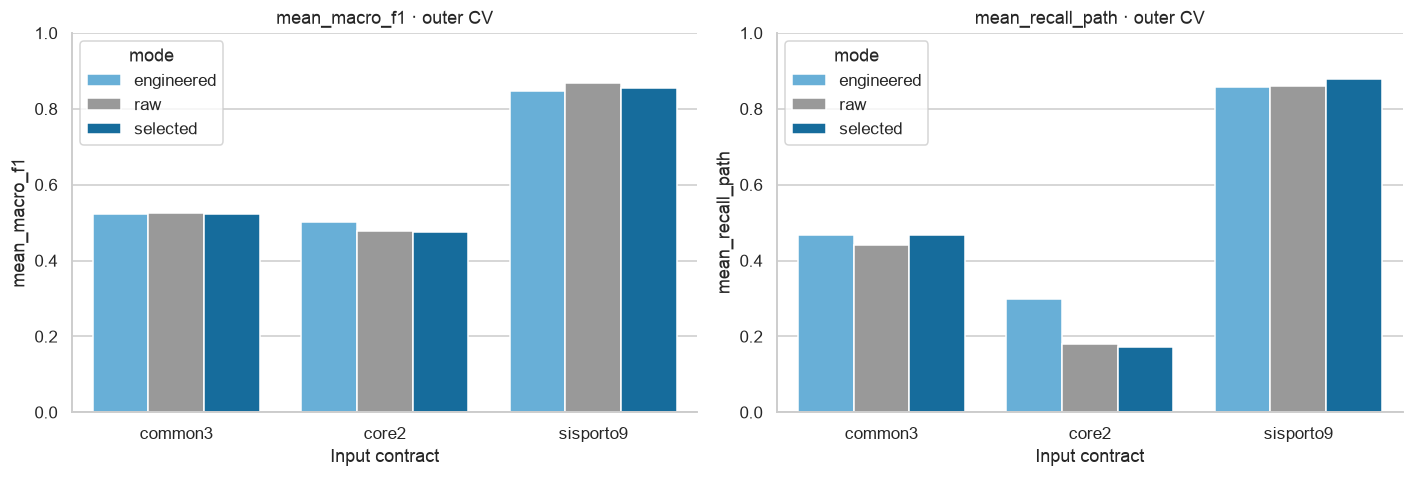

mode                  engineered     raw  selected
profile   outer_fold                              
common3   0               0.5812  0.5854    0.5854
          1               0.5668  0.6161    0.5668
          2               0.4422  0.4318    0.4422
          3               0.5261  0.5175    0.5261
          4               0.4912  0.4807    0.4912
core2     0               0.5164  0.5085    0.5085
          1               0.5675  0.4352    0.4352
          2               0.4227  0.4292    0.4227
          3               0.5008  0.5053    0.5053
          4               0.5009  0.5136    0.5009
sisporto9 0               0.8255  0.8784    0.8255
          1               0.8879  0.9058    0.8879
          2               0.7589  0.7762    0.7762
          3               0.8683  0.8891    0.8891
          4               0.8985  0.8923    0.8923

In [20]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,metric in zip(axes,['mean_macro_f1','mean_recall_path']):
    sns.barplot(data=summary,x='profile',y=metric,hue='mode',ax=ax,errorbar=None,
                palette={'raw':'#999999','engineered':'#56b4e9','selected':'#0072b2'})
    ax.set(ylim=(0,1),title=metric+' · outer CV',ylabel=metric,xlabel='Input contract')
fig.tight_layout();show_save('03_nested_comparison.png')
display(fold_metrics.pivot_table(index=['profile','outer_fold'],columns='mode',values='macro_f1').round(4))

### Финальные модели, ансамбли и известный test

Для каждого контракта выбирается свой лучший кандидат. Разные профили отвечают разным условиям доступности данных; 9-показательная модель не считается доступной на фотографии. Температура калибровки обучается на 341 validation-сегменте и не меняет класс argmax. Калибровка на другом устройстве не подтверждена. Validation-метрики выбранного ансамбля оптимистичны вследствие выбора на validation; смотрим также отдельный известный test и ограничения.

In [22]:
final_metrics,cards=run_final()
details=class_details()
intervals=bootstrap_results()
display(final_metrics[['profile','split','macro_f1','recall_suspect','recall_path','precision_path','ap_path','log_loss']].round(4))
display(final_metrics[['profile','split','file_macro_f1','file_recall_path','file_ap_path']].round(4))
display(cards[['profile','candidate','ensemble_accepted','members','temperature','scalers']])
display(details.round(4))
display(intervals.round(4))

Final core2: {'family': 'B_sqrt', 'engineered': True, 'params': {'depth': 3, 'iterations': 300, 'l2_leaf_reg': 10, 'learning_rate': 0.06}}, ensemble=False; 15.1s
Final common3: {'family': 'B_balanced', 'engineered': True, 'params': {'depth': 3, 'iterations': 600, 'l2_leaf_reg': 3, 'learning_rate': 0.06}}, ensemble=True; 24.5s
Final sisporto9: {'family': 'C_ovr', 'engineered': True, 'params': {'depth': 3, 'iterations': 600, 'l2_leaf_reg': 3, 'learning_rate': 0.06}}, ensemble=False; 44.2s


,profile,split,macro_f1,recall_suspect,recall_path,precision_path,ap_path,log_loss
0,core2,validation,0.5084,0.8478,0.0690,0.0870,0.1767,0.5830
1,core2,test,0.4744,0.6724,0.0286,0.0233,0.2119,0.5597
2,common3,validation,0.6677,0.9130,0.4828,0.7000,0.6396,0.4842
3,common3,test,0.5463,0.7931,0.3429,0.1765,0.2525,0.6070
4,sisporto9,validation,0.7614,0.6739,0.6897,0.7143,0.8469,0.2956
5,sisporto9,test,0.8436,0.7069,0.8857,0.7750,0.9222,0.2443


,profile,split,file_macro_f1,file_recall_path,file_ap_path
0,core2,validation,0.5730,0.1619,0.3945
1,core2,test,0.4537,0.0110,0.1940
2,common3,validation,0.6666,0.4176,0.5322
3,common3,test,0.5377,0.2850,0.2169
4,sisporto9,validation,0.7934,0.7514,0.8148
5,sisporto9,test,0.8606,0.8500,0.9141


,profile,candidate,ensemble_accepted,members,temperature,scalers
0,core2,"{'family': 'B_sqrt', 'engineered': True, 'params': {'depth': 3, 'iterations': 300, 'l2_leaf_reg': 10, 'learning_rate': 0.06}}",False,1,1.050925,none required for CatBoost; explicit empty scaler list saved
1,common3,"{'family': 'B_balanced', 'engineered': True, 'params': {'depth': 3, 'iterations': 600, 'l2_leaf_reg': 3, 'learning_rate': 0.06}}",True,5,0.934277,none required for CatBoost; explicit empty scaler list saved
2,sisporto9,"{'family': 'C_ovr', 'engineered': True, 'params': {'depth': 3, 'iterations': 600, 'l2_leaf_reg': 3, 'learning_rate': 0.06}}",False,1,1.476538,none required for CatBoost; explicit empty scaler list saved


,profile,NSP,precision,recall,f1,support,correct
0,core2,1,0.8618,0.7892,0.8239,332,262
1,core2,2,0.5000,0.6724,0.5735,58,39
2,core2,3,0.0233,0.0286,0.0256,35,1
3,common3,1,0.9122,0.7199,0.8047,332,239
4,common3,2,0.4842,0.7931,0.6013,58,46
5,common3,3,0.1765,0.3429,0.2330,35,12
6,sisporto9,1,0.9491,0.9548,0.9520,332,317
7,sisporto9,2,0.8039,0.7069,0.7523,58,41
8,sisporto9,3,0.7750,0.8857,0.8267,35,31


,profile,metric,lower,upper,valid_bootstraps
0,core2,macro_f1,0.4009,0.5350,2000
1,core2,recall_suspect,0.4594,0.8356,2000
2,core2,recall_path,0.0000,0.1668,2000
3,common3,macro_f1,0.4549,0.6231,2000
4,common3,recall_suspect,0.6250,0.9039,2000
5,common3,recall_path,0.0000,0.5333,2000
6,sisporto9,macro_f1,0.7349,0.9070,2000
7,sisporto9,recall_suspect,0.5167,0.8710,2000
8,sisporto9,recall_path,0.7000,0.9655,2000


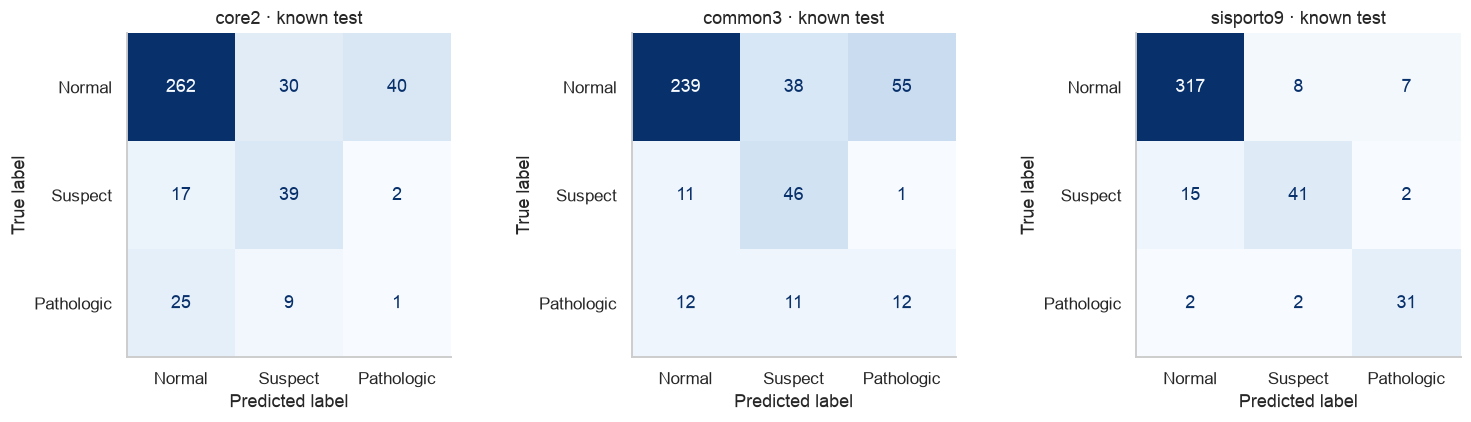

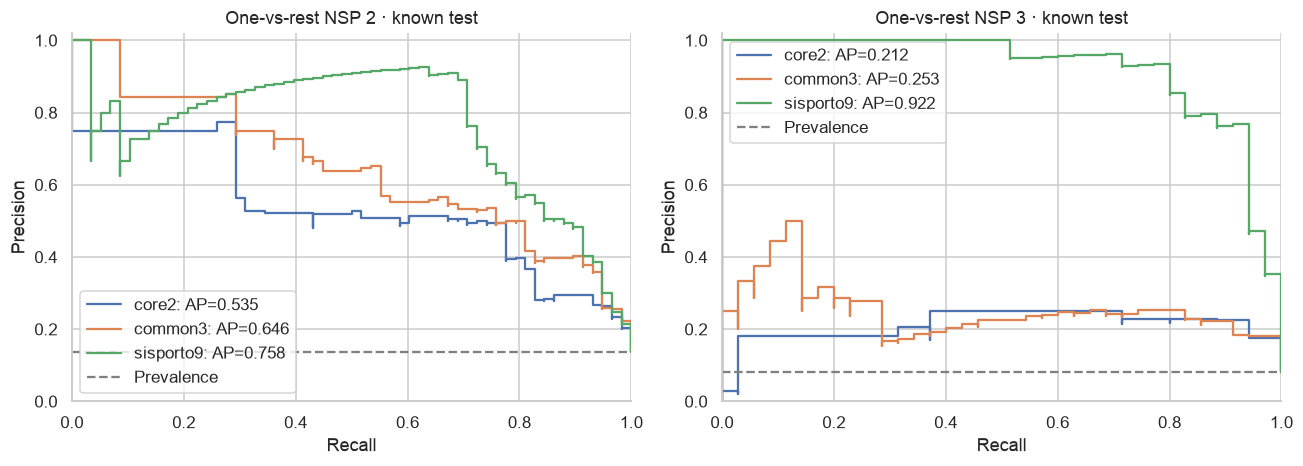

In [23]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,profile in zip(axes,PROFILES):
    cm=np.load(OUT/f'{profile}_test_confusion.npy')
    ConfusionMatrixDisplay(cm,display_labels=['Normal','Suspect','Pathologic']).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(profile+' · known test')
    ax.grid(False)
fig.tight_layout();show_save('04_test_confusion_matrices.png')
predictions=pd.read_parquet(OUT/'final_predictions.parquet')
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for label,ax in zip([2,3],axes):
    for profile in PROFILES:
        t=predictions[(predictions.profile==profile)&(predictions.split=='test')]
        precision,recall,_=precision_recall_curve(t.NSP==label,t[f'p{label-1}'])
        ap=average_precision_score(t.NSP==label,t[f'p{label-1}'])
        ax.step(recall,precision,where='post',label=f'{profile}: AP={ap:.3f}')
    ax.axhline((t.NSP==label).mean(),ls='--',color='grey',label='Prevalence')
    ax.set(xlim=(0,1),ylim=(0,1.02),xlabel='Recall',ylabel='Precision',title=f'One-vs-rest NSP {label} · known test');ax.legend()
fig.tight_layout();show_save('05_precision_recall.png')

### Сопоставление с полной моделью audited v2

Показываем потерю качества при ограничении измерений. У audited v2 отличается более широкий grid и процедура выбора калибровки/порогов; это описательный ориентир, а не чистая рандомизированная абляция. Чистое сравнение raw и engineering внутри нового эксперимента выше использует одинаковый grid и фолды. Test был известен ещё до этой ветки, поэтому значения не доказывают превосходство на будущих пациентках.

In [25]:
full=pd.read_csv(ROOT/'research/experiments/ctg_uci/audited_v2/test_metrics.csv')
display(full[['candidate','primary','macro_f1','recall_path','ap_path','file_macro_f1']].round(4))
display(final_metrics[final_metrics.split=='test'][['profile','macro_f1','recall_path','precision_path','ap_path','file_macro_f1']].round(4))

,candidate,primary,macro_f1,recall_path,ap_path,file_macro_f1
0,A_multiclass/single,False,0.8511,0.9143,0.9395,0.8645
1,B_sqrt/single,False,0.8806,0.9143,0.9222,0.8789
2,B_balanced/single,False,0.8838,0.9143,0.9089,0.8829
3,C_ovr/single,True,0.8538,0.9143,0.9103,0.8676
4,C_ovr/fold_ensemble,False,0.8593,0.9143,0.9284,0.8707
5,D_hierarchy/single,False,0.8454,0.9143,0.9403,0.8589
6,D_hierarchy/fold_ensemble,False,0.8413,0.9143,0.9299,0.8597
7,logistic/single,False,0.7748,0.6571,0.8059,0.7348


,profile,macro_f1,recall_path,precision_path,ap_path,file_macro_f1
1,core2,0.4744,0.0286,0.0233,0.2119,0.4537
3,common3,0.5463,0.3429,0.1765,0.2525,0.5377
5,sisporto9,0.8436,0.8857,0.7750,0.9222,0.8606


## Проверки кода, экспорта и научные границы

Проверка ниже независимо пересчитывает метрики из сохранённых предсказаний, сверяет номера строк/фолды/группы, проверяет SHA-256 bundle, inference после загрузки и единичный/batch режим. Скейлеры не дообучаются при predict. Требуемые пропуски и лишние поля с оценками отвергаются. Проводится отдельный набор тестов для единиц, временной информации и скейлера. Все результаты сохранены в ipynb.

Нативные `.cbm` — только деревья. Для корректного inference нужен bundle: контракт полей, engineering, подготовка, объединение голов и temperature. В файле schema указаны единицы и причина отсутствия скейлера у деревьев. Не заменять девять нативных измерений внешними похожими показателями.

Дополнительное ограничение исходной базы: LB в train находится только в диапазоне 106–160 BPM. Модель не проверена на всём диапазоне больничных КТГ. Метод bundle.support_report отмечает выходы за диапазон обучения; это проверка применимости, не медицинский порог. Даже отсутствие такого флага не доказывает совместимость другого прибора.

In [27]:
from tools.validate_ctg_report_models import validate
receipt=validate()
display(pd.Series(receipt,name='validation_receipt').to_frame())

,validation_receipt
fingerprint,54e923bb77b4598944f5b5075ab2f03f00aaf43d38364d92b534a83e2001ef1c
passed,True
nested_candidates,1380
inner_evaluations,4140
final_candidates,276
final_inner_evaluations,828
verified_predictions,"[common3/test, common3/validation, core2/test, core2/validation, sisporto9/test, sisporto9/validation]"
grouped_boundaries,True
same_outer_folds_as_v2,True
manual_arithmetic,True


## Дополнительный источник именно для дородового сценария

После уточнения назначения приложения найден [JNU-CTG, Zenodo, версия 1.0.0](https://zenodo.org/records/21800730). Ниже — отдельный аудит скачанного первоисточника. Его данные **не объединяются** с UCI и не меняют уже выбранные модели.

Документация описывает дородовые записи и идентификаторы пациенток. В доступной разметке FIGO только normal/abnormal; это не трёхклассовый NSP. Исход neonatal_asphyxia — другой endpoint. Числа поддержки и пропусков проверены по CSV, содержимое и MD5 сверены с опубликованным архивом.

Полей F_STV/F_LTV по названию недостаточно для сопоставления с фотографией: нужны единицы и реализация экстрактора. Также нельзя добавлять в дородовую модель Apgar, родоразрешение, послеродовые признаки или неизвестно как обученные NetFea. В документации gestational_age описан при родах; это не подтверждённый срок на момент каждого КТГ. Источник перспективнее для следующего дородового исследования, но не устраняет внешнюю проверку устройств.

In [29]:
from src.features.ctg_jnu_candidate import audit_jnu
support_jnu,ranges_jnu,jnu_receipt,wave_jnu=audit_jnu()
display(support_jnu)
display(ranges_jnu.round(4))
display(pd.Series({k:v for k,v in jnu_receipt.items() if k not in ['blockers']},name='source_audit').to_frame())
display(pd.DataFrame({'measurement_or_design_gap':jnu_receipt['blockers']}))

,target,label,recordings,patients_with_label,missing_target
0,figo_label,0,9598,7270,0
1,figo_label,1,11171,8342,0
2,neonatal_asphyxia,0,20557,12477,58
3,neonatal_asphyxia,1,154,91,58


,count,mean,std,min,25%,50%,75%,max
F_BL,20769.0,139.3747,8.1832,98.0908,134.0742,139.0029,144.3833,184.1604
F_A_N,20769.0,13.1817,6.3707,0.0000,8.0000,13.0000,17.0000,43.0000
F_D_N,20769.0,1.1295,1.8348,0.0000,0.0000,0.0000,2.0000,19.0000
F_LTV,20769.0,16.8006,0.4808,13.5667,16.4863,16.7853,17.1057,19.2264
F_STV,20769.0,2.6170,0.8854,0.0070,2.0143,2.5310,3.1225,11.4542


,source_audit
source,https://zenodo.org/records/21800730
doi,10.5281/zenodo.21800730
archive_md5,ac1cfcba2f1b3336596544211d776771
archive_sha256,6efe9ce43f5ef803eb4ef65c87892e1a768899ff3bb82de56c18c834d5e09a98
archive_members_checked,True
waveform_count,20769
rows,20769
columns,215
unique_patients,12606
license_file,CC BY 4.0 text included inside archive


,measurement_or_design_gap
0,F_STV/F_LTV names do not document equality to the hospital extractor
1,Binary FIGO normal/abnormal cannot validate separate suspect/pathologic classes
2,Rare neonatal outcome is distinct from morphology and UCI NSP
3,Delivery and neonatal columns are unavailable at antenatal prediction time
4,Gestational age is described at delivery; recording-time gestation must be established
5,Single center; independent device and clinical validation still needed


### Маски на исходном сигнале

В этом источнике нулевой FHR — код пропуска, в отличие от нуля числа акцелераций в UCI. На одном реальном цифровом примере показываем разрывы после маски FHR=0. Нули UC автоматически не маскируем: значение может быть настоящим. Не интерполируем длинные разрывы и не называем производные собственным STV производителя.

FHR zero/missing fraction in this recording: 0.007916666666666667


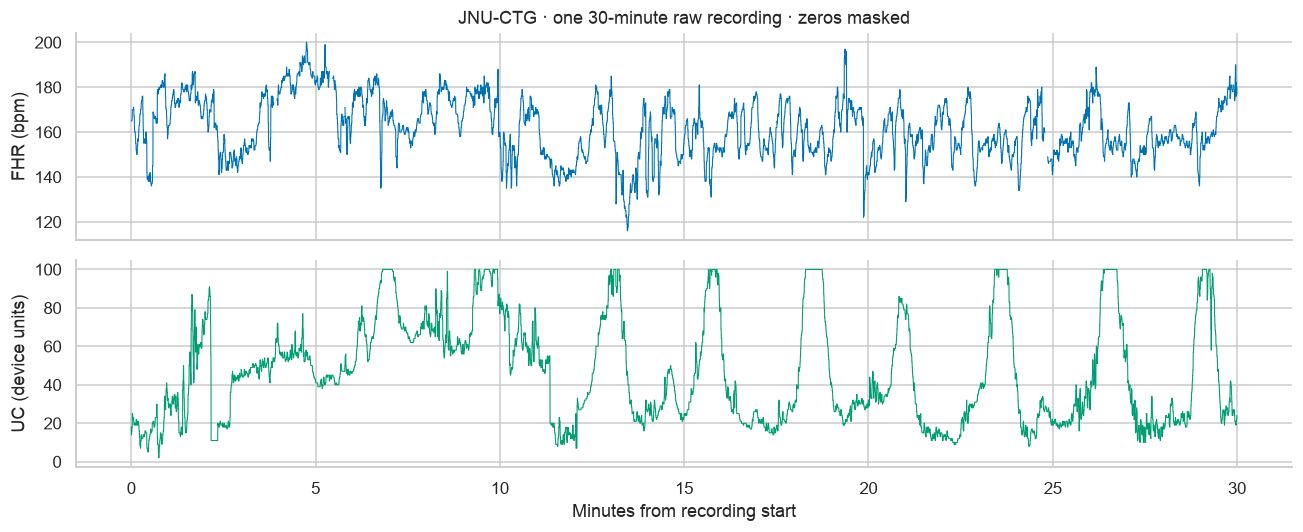

In [31]:
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
time_min=np.arange(len(wave_jnu))/4/60
fhr=wave_jnu.FHR.mask(wave_jnu.FHR==0)
axes[0].plot(time_min,fhr,lw=.7,color='#0072b2');axes[0].set(ylabel='FHR (bpm)',title='JNU-CTG · one 30-minute raw recording · zeros masked')
axes[1].plot(time_min,wave_jnu.UC,lw=.7,color='#009e73');axes[1].set(ylabel='UC (device units)',xlabel='Minutes from recording start')
fig.tight_layout();show_save('06_antenatal_raw_signal_mask.png')
print('FHR zero/missing fraction in this recording:',float((wave_jnu.FHR==0).mean()))

## Takeaways · приложение для ведения беременности

1. Зафиксировать конкретную клиническую задачу, срок/контекст, аппарат и версию ПО; получить его определения и способ выгрузки исходного цифрового сигнала/сводки. Одна фотография не определяет универсальный формат.
2. На одних и тех же записях сопоставить измерения устройства и учебного экстрактора: окна, потери, детекторы, единицы, длительность. Проверить смещения/согласие; это отдельная проверка измерений, а не CV классификатора.
3. Собрать размеченные обезличенные больничные записи с ID пациентки, независимой экспертной разметкой и заранее выбранным клиническим исходом. Достаточное число патологических пациенток важнее числа похожих сегментов; размер рассчитывается под требуемую точность recall и внешнюю проверку.
4. Учить/калибровать на реальных STV/LTV/ВКИ и масках качества в этом датасете. Разделять по пациенткам, затем по времени/центру/прибору; внешняя проверка должна быть закрыта до фиксации pipeline и порогов. Оценить и подозрительные, и патологические случаи, пропуски тяжёлых случаев, PPV, калибровку, подгруппы и долю отказов.
5. Для цифровых КТГ можно сделать единый версионированный экстрактор и применять его и к обучению, и к новым сигналам. Доступная в проекте CTU-UHB относится к родам и другим исходам; нельзя смешивать её pH с UCI NSP и выдавать результат за проверенную дородовую модель.

### Решение по применению

Готовые экспортированные модели пригодны для воспроизводимого исследования UCI с соответствующими измерениями. **Для автоматической медицинской оценки бланка на фотографии подтверждения пока нет.** Удобный ввод подготовлен; формальная возможность посчитать число не является доказательством, что оно корректно на другом устройстве.